<center><h1>Blombach_George_HW8</h1></center>

Name: George Blombach | Github Username: gblombach | USC ID: 2416-0961-99

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, \
    f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, pairwise_distances
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans, SpectralClustering

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
#569 instance, 32 total attributes; diagnosis: 357 Benign, 212 Malignant
raw_data = pd.read_csv("../data/wdbc.data", header = None)
#display(raw_data.shape)
mapping = {'M':1, 'B':0}                      #define Malignant/Benign to 1/0 mapping
data = raw_data.copy()
data.columns = ["ID","Diagnosis"] + [f'attr{i}' for i in range(1,31)]
data['Diagnosis'] = data['Diagnosis'].map(mapping) # replace M/B with 1/0 
#print(raw_data.head())
#print(data.head())

### (b) Monte-Carlo Simulation

In [3]:
# setup data
y = data['Diagnosis'].copy()
X = data.drop(columns=['ID','Diagnosis']).copy()
M = 30                                           #number of monte carlo simulations
C_grid = np.logspace(-4, 4, 9)                   #Candidate penalty parameters for  L1-penalized SVM
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
results = []
# Function for deriving metrics
def calc_metrics(y_true, y_pred, scores):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0), "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
            "AUC": roc_auc_score(y_true, scores)}
# Function for ROC and Confusion Matrix
def show_roc_and_cm(y_train, y_test, train_pred, test_pred, train_scores, test_scores, method):
    print("Representative Run for", method,":")
    fig, axes = plt.subplots(nrows=1,ncols=4,figsize=(20, 4))
    ConfusionMatrixDisplay.from_predictions(y_train, train_pred, labels=[0, 1], display_labels=["Benign", "Malignant"], cmap="Blues", colorbar=False, ax=axes[0])
    ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=[0, 1], display_labels=["Benign", "Malignant"], cmap="Blues", colorbar=False, ax=axes[1])
    axes[0].set_title(f"{method}: Training", fontsize=14)
    axes[1].set_title(f"{method}: Testing", fontsize=14)
    fpr, tpr, _ = roc_curve(y_train, train_scores)                   #ROC 
    train_auc = roc_auc_score(y_train, train_scores)
    axes[2].plot(fpr, tpr, linewidth=2, label=f"AUC = {train_auc:.3f}")
    axes[2].set_title(f"{method}: Training ROC", fontsize=14)
    fpr, tpr, _ = roc_curve(y_test, test_scores)
    test_auc = roc_auc_score(y_test, test_scores)
    axes[3].plot(fpr, tpr, linewidth=2, label=f"AUC = {test_auc:.3f}")
    axes[3].set_title(f"{method}: Testing ROC", fontsize=14)
    for ax in axes[2:4]:
        ax.set_xlabel("False Positive Rate", fontsize=12)
        ax.set_ylabel("True Positive Rate", fontsize=12)
        ax.plot([0, 1], [0, 1],linestyle=":", color="gray", alpha=0.6)
        ax.legend(fontsize=12, loc='lower right')
    for ax in axes:
        ax.tick_params(axis="both", labelsize=8)
        ax.xaxis.label.set_size(12)
        ax.yaxis.label.set_size(12)
    plt.tight_layout()
    plt.show()

#### (i) Supervised Learning

Representative Run for Supervised SVM :


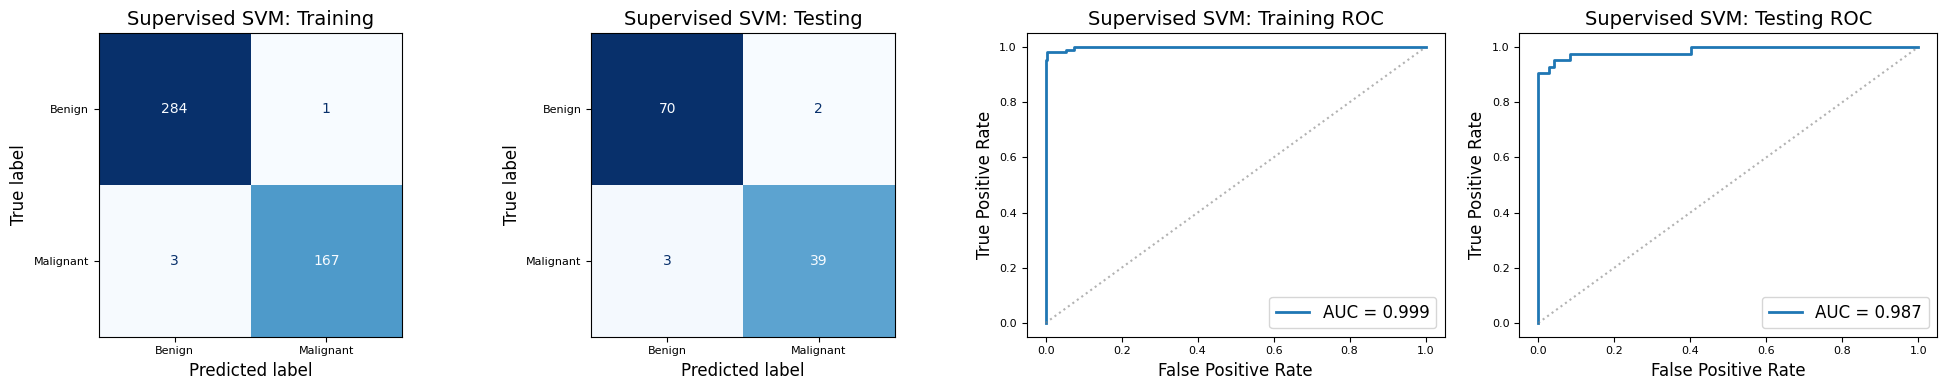

In [4]:
# Function for 5 fold cross validation  
def fit_l1_svm(X_train, y_train, random_state):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    pipeline = Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(penalty="l1", dual=False,
            max_iter=10000, tol=1e-3, random_state=random_state))])
    grid_search = GridSearchCV(estimator=pipeline, param_grid={"svm__C": C_grid},  scoring="accuracy", cv=cv, n_jobs=-1)
    grid_search.fit(X_train, y_train)
    return (grid_search.best_estimator_)
# split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=333)
# function to evaluate model
def evaluate_supervised(X_train, X_test, y_train, y_test, random_state):
    supervised_model = fit_l1_svm(X_train, y_train, random_state=random_state) # fit model
    supervised_train_pred = supervised_model.predict(X_train)                  # training predictions
    supervised_test_pred = supervised_model.predict(X_test)                    # test predictions
    supervised_train_scores = (supervised_model.decision_function(X_train))    # training scores
    supervised_test_scores = (supervised_model.decision_function(X_test))      # test scores 
    supervised_train_metrics = calc_metrics(y_train, supervised_train_pred, supervised_train_scores) # training metrics
    supervised_test_metrics = calc_metrics(y_test, supervised_test_pred, supervised_test_scores)     # test metrics
    return (supervised_train_metrics, supervised_test_metrics, supervised_train_pred, supervised_test_pred, 
            supervised_train_scores, supervised_test_scores)
# perform representive run
(supervised_train_metrics, supervised_test_metrics, supervised_train_pred, supervised_test_pred, supervised_train_scores,
    supervised_test_scores) = evaluate_supervised(X_train, X_test, y_train, y_test, random_state=333)
# show ROC and confusion matrix for representative run
show_roc_and_cm(y_train, y_test, supervised_train_pred, supervised_test_pred, supervised_train_scores,supervised_test_scores , "Supervised SVM")   

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [5]:
def fit_self_l1_svm(X_labeled, y_labeled, X_unlabeled,  random_state):
    initial_model = fit_l1_svm(X_labeled, y_labeled,  random_state)  # Choose C using 5-fold CV on the initial labeled set
    best_C = initial_model.named_steps["svm"].C
    # Final self-training pipeline using the selected C
    model = Pipeline([("scaler", StandardScaler()),("svm", LinearSVC(penalty="l1", dual=False, C=best_C, max_iter=10000,
                tol=1e-3, random_state=random_state))])
    X_labeled = X_labeled.copy().reset_index(drop=True)
    y_labeled = y_labeled.copy().reset_index(drop=True)
    X_unlabeled = X_unlabeled.copy().reset_index(drop=True)
    while len(X_unlabeled) > 0:
        model.fit(X_labeled, y_labeled)                           # Retrain using the current labeled set
        unlabeled_scores = model.decision_function(X_unlabeled)   # Find the distance of every unlabeled observation
                                                                  # from the SVM decision boundary
        farthest_idx = np.argmax(np.abs(unlabeled_scores))        # The largest absolute score is farthest from
        selected_point = X_unlabeled.iloc[[farthest_idx]]         # the decision boundary
        pseudo_label = model.predict(selected_point)[0]           # Use the SVM's prediction, not the true label
        X_labeled = pd.concat([X_labeled, selected_point],ignore_index=True)   # Add the selected point and pseudo-label
        y_labeled = pd.concat([y_labeled, pd.Series([pseudo_label], name=y_labeled.name)],ignore_index=True)
        X_unlabeled = (X_unlabeled.drop(X_unlabeled.index[farthest_idx]).reset_index(drop=True)) # remove the point
    model.fit(X_labeled, y_labeled)                               # Final fit after all unlabeled observations are added
    return model
#function to split data
def split_labeled_unlabeled(X_train, y_train, random_state):
    rng = np.random.default_rng(random_state)
    X_train = X_train.copy().reset_index(drop=True)                      # Reset indices to align positions
    y_train = y_train.copy().reset_index(drop=True)
    positive_idx = np.where(y_train.to_numpy() == 1)[0]
    negative_idx = np.where(y_train.to_numpy() == 0)[0]           # Randomly select 50% of each class as labeled
    labeled_positive_idx = rng.choice(positive_idx,size=len(positive_idx) // 2, replace=False)
    labeled_negative_idx = rng.choice(negative_idx,size=len(negative_idx) // 2, replace=False)
    labeled_idx = np.concatenate([labeled_positive_idx, labeled_negative_idx])
    rng.shuffle(labeled_idx)
    unlabeled_idx = np.setdiff1d(np.arange(len(X_train)), labeled_idx)
    X_labeled = (X_train.iloc[labeled_idx].reset_index(drop=True))
    y_labeled = (y_train.iloc[labeled_idx].reset_index(drop=True))
    X_unlabeled = (X_train.iloc[unlabeled_idx].reset_index(drop=True))
    return X_labeled, y_labeled, X_unlabeled

##### (B)

Representative Run for Semi-Supervised SVM :


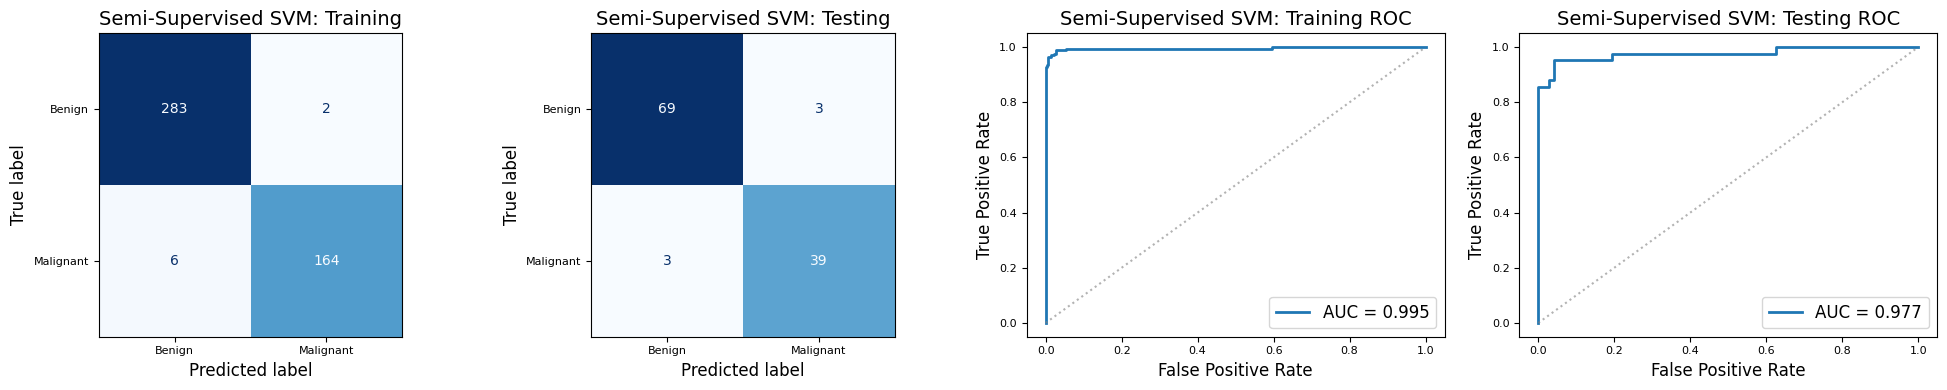

In [6]:
#Perform representative run
def evaluate_semi_supervised(X_train, X_test, y_train, y_test, random_state):
    # Select 50% of each training class as labeled
    X_labeled, y_labeled, X_unlabeled = (split_labeled_unlabeled(X_train, y_train, random_state=random_state))
    semi_supervised_model = fit_self_l1_svm(X_labeled,y_labeled, X_unlabeled, random_state=random_state)
    semi_train_pred = semi_supervised_model.predict(X_train)                          #training prediction
    semi_train_scores = (semi_supervised_model.decision_function(X_train))            #training scores
    semi_test_pred = semi_supervised_model.predict(X_test)                            #testing predictions 
    semi_test_scores = (semi_supervised_model.decision_function(X_test))              #testing decision scores
    semi_train_metrics = calc_metrics(y_train, semi_train_pred, semi_train_scores)    #training metrics
    semi_test_metrics = calc_metrics(y_test, semi_test_pred, semi_test_scores)        #test metrics
    return(semi_train_metrics, semi_test_metrics, semi_train_pred, semi_test_pred, semi_train_scores, semi_test_scores)
#Perform representative run
(semi_train_metrics, semi_test_metrics, semi_train_pred, semi_test_pred, semi_train_scores, semi_test_scores) \
    = evaluate_semi_supervised(X_train, X_test, y_train, y_test, random_state=333)
# show results
show_roc_and_cm(y_train, y_test, semi_train_pred,semi_test_pred, semi_train_scores,semi_test_scores,"Semi-Supervised SVM")

#### (iii) Unsupervised Learning

##### (A)

In [7]:
# Function to fit K-means
def fit_kmeans(X_train, random_state):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    kmeans = KMeans(n_clusters=2, init="random", n_init=50, random_state=random_state) #run 50 times
    kmeans.fit(X_train_scaled)
    return scaler, kmeans

K-means was run 50 times using different random initializations. The solution with the lowest within-cluster sum of squared distances (inertia) was retained, reducing the likelihood of selecting a poor local minimum.

##### (B)

Representative Run for Unsupervised K-Means :


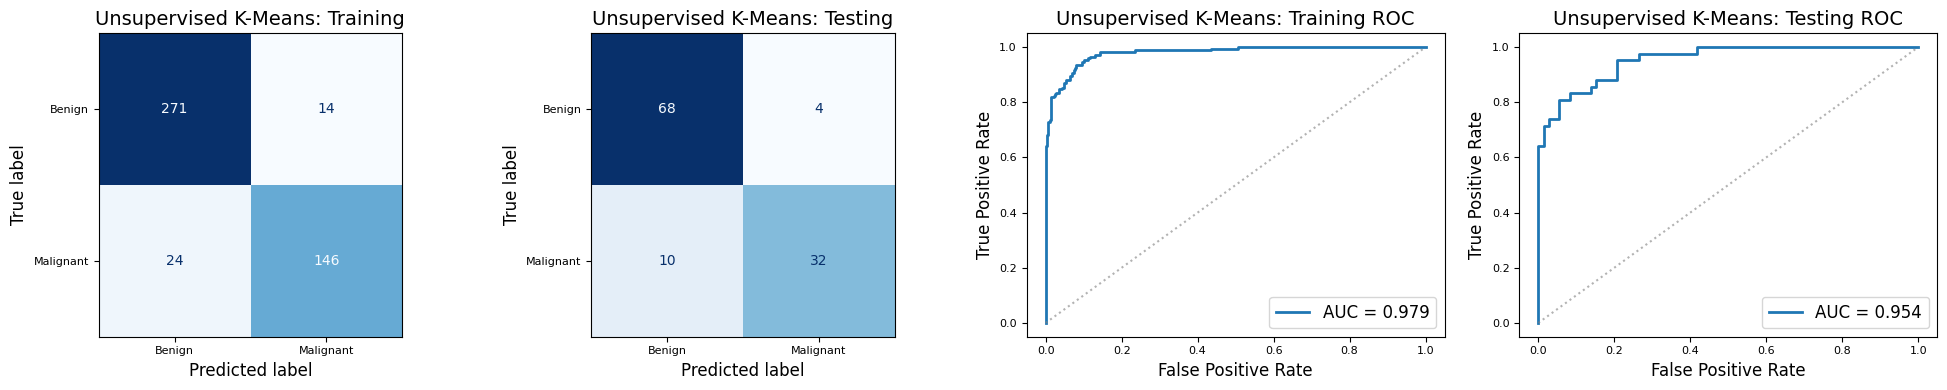

In [8]:
# Function to assign a class to each cluster
def assign_cluster_labels(kmeans, X_train_scaled, y_train):
    cluster_labels = {}
    for cluster in range(2):
        cluster_idx = np.where(kmeans.labels_ == cluster)[0]       #Observations belonging to this cluster
        # Distance from observations to this cluster's center
        distances = np.linalg.norm(X_train_scaled[cluster_idx] - kmeans.cluster_centers_[cluster],axis=1)
        closest_idx = cluster_idx[np.argsort(distances)[:30]]      #Find the 30 closest observations
        majority_label = y_train.iloc[closest_idx].mode().iloc[0]  #Find the majority class
        cluster_labels[cluster] = majority_label
    return cluster_labels
# Function for training predictions
def predict_kmeans_train(kmeans, cluster_labels):
    cluster_pred = kmeans.labels_
    y_pred = np.array([cluster_labels[cluster] for cluster in cluster_pred])
    return y_pred
# Function for test predictions
def predict_kmeans_test(kmeans, X_test_scaled, cluster_labels):
    cluster_pred = kmeans.predict(X_test_scaled)
    y_pred = np.array([cluster_labels[cluster] for cluster in cluster_pred])
    return y_pred    
# Function to calculate K-means scores
def get_kmeans_scores(kmeans, X_scaled, cluster_labels):
    distances = kmeans.transform(X_scaled)
    malignant_cluster = [cluster for cluster, label in cluster_labels.items() if label == 1][0]
    benign_cluster = [cluster for cluster, label in cluster_labels.items() if label == 0][0]
    scores = (distances[:, benign_cluster] - distances[:, malignant_cluster])
    return scores
#define function for evaluating unsupervised
def evaluate_unsupervised(X_train, X_test, y_train, y_test, random_state):
    scaler, kmeans = fit_kmeans(X_train, random_state)
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    cluster_labels = assign_cluster_labels(kmeans, X_train_scaled, y_train)         # assign class closest to center
    unsup_train_pred = predict_kmeans_train(kmeans, cluster_labels)                 # training predictions
    unsup_train_scores = get_kmeans_scores(kmeans, X_train_scaled, cluster_labels)  # training scores
    unsup_test_pred = predict_kmeans_test(kmeans, X_test_scaled, cluster_labels)    # test predictions
    unsup_test_scores = get_kmeans_scores(kmeans, X_test_scaled, cluster_labels)    # test scores
    unsup_train_metrics = calc_metrics(y_train, unsup_train_pred, unsup_train_scores)
    unsup_test_metrics = calc_metrics(y_test, unsup_test_pred, unsup_test_scores)
    return(unsup_train_metrics, unsup_test_metrics, unsup_train_pred, unsup_test_pred, unsup_train_scores, unsup_test_scores)
# Perform representative run
(unsup_train_metrics, unsup_test_metrics, unsup_train_pred, unsup_test_pred, unsup_train_scores, unsup_test_scores) \
= evaluate_unsupervised(X_train, X_test, y_train, y_test, random_state=333)
# Show ROC curves and confusion matrices for the representative run
show_roc_and_cm(y_train,y_test,unsup_train_pred,unsup_test_pred,unsup_train_scores,unsup_test_scores,"Unsupervised K-Means")

#### (iv) Spectral Clustering

Target Class Sizes: [170 285]
Gamma = 1 Cluster Sizes: [  2 453]
Best Gamma Cluster Sizes: [159 296]
Best Gamma Tested: 1e-05
Cluster Labels: {0: 1, 1: 0}
Representative Run for Spectral Clustering :


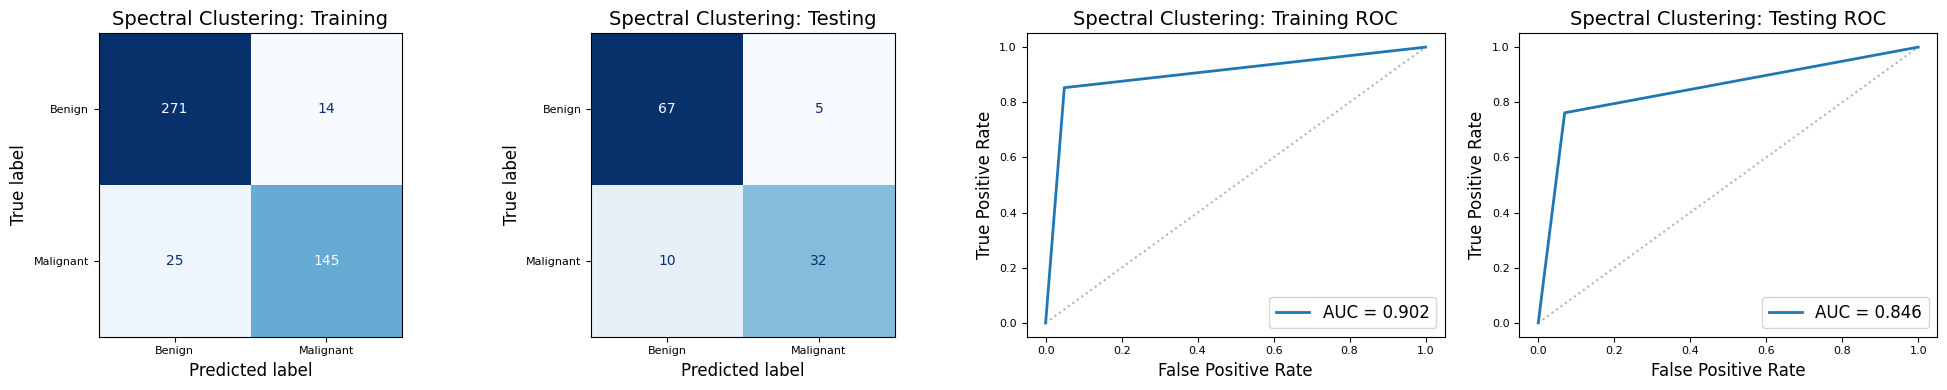

In [9]:
#reworked Function to find gamma with cluster sizes closest to the original class balance
def evaluate_spectral(X_train, X_test, y_train, y_test, random_state):
    # Scale using training data only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    y_train_array = np.asarray(y_train)

    # Desired cluster sizes based on the original class balance
    target_sizes = np.sort(np.bincount(y_train_array, minlength=2))
    gamma_grid = np.logspace(-5, 0, 100)
    best_gamma = None
    best_difference = np.inf
    train_clusters = None
    # Find gamma with cluster sizes closest to class sizes
    for gamma in gamma_grid:
        spectral = SpectralClustering(n_clusters=2, affinity="rbf", gamma=gamma, assign_labels="kmeans", n_init=50, random_state=random_state)
        candidate_clusters = spectral.fit_predict(X_train_scaled)                # use fit-predict method
        cluster_sizes = np.sort(np.bincount(candidate_clusters, minlength=2))
        difference = np.abs(cluster_sizes - target_sizes).sum()
        if difference < best_difference:
            best_difference = difference
            best_gamma = gamma
            train_clusters = candidate_clusters.copy()
        # Stop if an exact size match is found
        if difference == 0:
            break
    # Use all points in each cluster for majority polling
    cluster_positive_rates = {cluster: y_train_array[train_clusters == cluster].mean() for cluster in [0, 1]}
    # Each training observation receives its cluster's positive-class polling proportion
    train_scores = np.array([cluster_positive_rates[cluster] for cluster in train_clusters])
    train_pred = (train_scores >= 0.5).astype(int)                                 # Majority polling at threshold 0.5
    distances = pairwise_distances(X_test_scaled, X_train_scaled)                  # Assign each test point to the cluster 
    nearest_train_idx = distances.argmin(axis=1)                                   # of its nearest training observation
    test_clusters = train_clusters[nearest_train_idx]                              
    test_scores = np.array([cluster_positive_rates[cluster] for cluster in test_clusters])    # Test observations receive the polling proportion
    test_pred = (test_scores >= 0.5).astype(int)                                              # of their assigned training cluster
    train_metrics = calc_metrics(y_train, train_pred, train_scores)                # Calculate metrics
    test_metrics = calc_metrics(y_test, test_pred, test_scores)
    if random_state == 333:
        # Gamma = 1
        spectral_gamma1 = SpectralClustering(n_clusters=2, affinity="rbf", gamma=1, assign_labels="kmeans", n_init=50, random_state=333)
        clusters_gamma1 = spectral_gamma1.fit_predict(X_train_scaled)
        print("Target Class Sizes:", target_sizes)
        print("Gamma = 1 Cluster Sizes:", np.sort(np.bincount(clusters_gamma1, minlength=2)))
        print("Best Gamma Cluster Sizes:", np.bincount(train_clusters, minlength=2))
        print("Best Gamma Tested:", best_gamma)
        print("Cluster Labels:",{cluster: int(rate >= 0.5) for cluster, rate in cluster_positive_rates.items()})
    return(train_metrics, test_metrics, train_pred, test_pred, train_scores, test_scores)
#representative run
(spectral_train_metrics,spectral_test_metrics,spectral_train_pred, spectral_test_pred, spectral_train_scores, spectral_test_scores) \
= evaluate_spectral(X_train, X_test, y_train, y_test, random_state=333)
# roc and cm
show_roc_and_cm(y_train, y_test, spectral_train_pred, spectral_test_pred, spectral_train_scores, spectral_test_scores, "Spectral Clustering")

#### (v) Compare

In [10]:
# helper function for gathering metrics
def add_results(results, run, method, train_metrics, test_metrics):
    results.append({"Run": run + 1,"Method": method,"Dataset": "Training", **train_metrics})
    results.append({"Run": run + 1,"Method": method,"Dataset": "Testing", **test_metrics})
# Monte Carlo simulation for all four methods
#M = 2
for run in range(M):
    random_state = run
    # Use the same stratified 80/20 split for all models in this run
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=random_state)
    (supervised_train_metrics, supervised_test_metrics, supervised_train_pred, supervised_test_pred, supervised_train_scores, supervised_test_scores) \
    = evaluate_supervised(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Supervised L1-SVM", supervised_train_metrics, supervised_test_metrics)
    (semi_train_metrics, semi_test_metrics, semi_train_pred, semi_test_pred, semi_train_scores, semi_test_scores) \
    = evaluate_semi_supervised(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Semi-Supervised L1-SVM", semi_train_metrics, semi_test_metrics)
    (unsup_train_metrics, unsup_test_metrics, unsup_train_pred, unsup_test_pred, unsup_train_scores, unsup_test_scores) \
    = evaluate_unsupervised(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Unsupervised K-Means", unsup_train_metrics, unsup_test_metrics)
    (spectral_train_metrics, spectral_test_metrics, spectral_train_pred, spectral_test_pred, spectral_train_scores, spectral_test_scores) \
    = evaluate_spectral(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Spectral Clustering", spectral_train_metrics, spectral_test_metrics)
    #print(f"Completed run {run + 1} of {M}")

In [11]:
results_df = pd.DataFrame(results)
summary = (results_df.groupby(["Method", "Dataset"])[metrics].agg(["mean", "std"]))
comparison_table = pd.DataFrame()
for metric in metrics:
    for dataset in ["Training", "Testing"]:
        comparison_table[f"{dataset} {metric}"] = (summary.loc[(slice(None), dataset), (metric, "mean")]
            .droplevel("Dataset").map("{:.4f}".format) + " ± " + summary.loc[(slice(None), dataset), (metric, "std")]
            .droplevel("Dataset").map("{:.4f}".format))
print("Mean ± Standard Deviation Comparison Over", M, "Monte Carlo Runs:")
display(comparison_table)

Mean ± Standard Deviation Comparison Over 30 Monte Carlo Runs:


,Training Accuracy,Testing Accuracy,Training Precision,Testing Precision,Training Recall,Testing Recall,Training F1,Testing F1,Training AUC,Testing AUC
Method,,,,,,,,,,
Semi-Supervised L1-SVM,0.9775 ± 0.0079,0.9614 ± 0.0184,0.9827 ± 0.0126,0.9656 ± 0.0302,0.9569 ± 0.0200,0.9294 ± 0.0417,0.9694 ± 0.0110,0.9464 ± 0.0262,0.9948 ± 0.0025,0.9920 ± 0.0075
Spectral Clustering,0.9084 ± 0.0053,0.9079 ± 0.0221,0.9201 ± 0.0102,0.9129 ± 0.0311,0.8269 ± 0.0144,0.8302 ± 0.0551,0.8709 ± 0.0081,0.8684 ± 0.0343,0.8920 ± 0.0067,0.8917 ± 0.0279
Supervised L1-SVM,0.9868 ± 0.0047,0.9673 ± 0.0138,0.9914 ± 0.0060,0.9737 ± 0.0266,0.9731 ± 0.0090,0.9373 ± 0.0334,0.9822 ± 0.0064,0.9546 ± 0.0196,0.9973 ± 0.0016,0.9931 ± 0.0067
Unsupervised K-Means,0.9102 ± 0.0059,0.9053 ± 0.0210,0.9238 ± 0.0154,0.9096 ± 0.0322,0.8282 ± 0.0158,0.8262 ± 0.0538,0.8732 ± 0.0085,0.8647 ± 0.0332,0.9749 ± 0.0031,0.9719 ± 0.0124


##### Observation:

- The results support the expected relationship among the learning methods. Over 30 Monte Carlo runs, the *supervised L1-SVM had the best overall test performance*, with mean accuracy of 0.9673, precision of 0.9737, recall of 0.9373, F1-score of 0.9546, and AUC of 0.9931.
- The semi-supervised L1-SVM performed slightly worse, with corresponding test values of 0.9614, 0.9656, 0.9294, 0.9464, and 0.9920.
- Both unsupervised approaches performed noticeably worse than the supervised and semi-supervised methods. Spectral clustering obtained a mean test accuracy of 0.9079 and F1-score of 0.8684, while K-means obtained a mean test accuracy of 0.9053 and F1-score of 0.8647.
- The two unsupervised methods performed similarly overall, although K-means had a slightly higher test AUC than spectral clustering (0.9719 versus 0.9642).

Therefore, **the results are consistent with the expectation** that using all available training labels produces the strongest performance, using only half of the training labels produces slightly lower performance, and unsupervised learning generally underperforms both label-based approaches.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [12]:
banknote_data = pd.read_csv("../data/data_banknote_authentication.txt", header = None, names=["variance", "skewness", "curtosis", "entropy", "class"])
#banknote_data.head()
X = banknote_data.drop(columns="class")
y = banknote_data["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=472, random_state=333)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 900
Testing observations: 472


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [13]:
# function for passive learning
def passive_learning(X_train, y_train, X_test, y_test, C_grid, random_state):
    rng = np.random.default_rng(random_state)
    y_array = y_train.to_numpy()
    class_0 = np.where(y_array == 0)[0]
    class_1 = np.where(y_array == 1)[0]
    # use 5 observations from each class in initial observation, so both classes have enough observations for 5-fold CR
    initial_pool = np.concatenate([rng.choice(class_0, size=5, replace=False), rng.choice(class_1, size=5, replace=False)])
    rng.shuffle(initial_pool)
    remaining = np.setdiff1d(np.arange(len(X_train)), initial_pool)  # randomly order remaining items after removing initial ones
    rng.shuffle(remaining)
    acquisition_order = np.concatenate([initial_pool, remaining ])
    errors = []
    for pool_size in range(10, 901, 10):
        pool_idx = acquisition_order[:pool_size]
        X_pool = X_train.iloc[pool_idx]
        y_pool = y_train.iloc[pool_idx]
        model = Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(penalty="l1",loss="squared_hinge", dual=False, max_iter=100000, random_state=random_state))])
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
        grid = GridSearchCV(estimator=model, param_grid={"svm__C": C_grid}, scoring="accuracy", cv=cv, n_jobs=-1)
        grid.fit(X_pool, y_pool)
        test_error = 1 - grid.score(X_test, y_test)
        errors.append(test_error)
    return errors


In [14]:
# execute passive learning and display
C_grid = np.logspace(-3, 6, 20)
passive_run = passive_learning(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test, C_grid=C_grid, random_state=333)
passive_results = pd.DataFrame([np.arange(10, 901, 10), passive_run],index=["Training Size", "Test Error"])
print("Passive Learning Representative Run:")
display(passive_results.style.format("{:.6f}", subset=pd.IndexSlice["Test Error", :]).format("{:.0f}", subset=pd.IndexSlice["Training Size", :]))

Passive Learning Representative Run:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89
Training Size,10,20,30,40,50,60,70,80,90,100,110,120,130,140,150,160,170,180,190,200,210,220,230,240,250,260,270,280,290,300,310,320,330,340,350,360,370,380,390,400,410,420,430,440,450,460,470,480,490,500,510,520,530,540,550,560,570,580,590,600,610,620,630,640,650,660,670,680,690,700,710,720,730,740,750,760,770,780,790,800,810,820,830,840,850,860,870,880,890,900
Test Error,0.141949,0.095339,0.042373,0.008475,0.012712,0.012712,0.012712,0.021186,0.019068,0.019068,0.023305,0.008475,0.006356,0.010593,0.006356,0.006356,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.008475,0.014831,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.019068,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593


#### (ii) Active

In [15]:
# function for active learning 
def active_learning(X_train, y_train, X_test, y_test, C_grid, random_state):
    rng = np.random.default_rng(random_state)
    y_array = np.asarray(y_train).ravel()
    classes = np.unique(y_array)
    class_0_indices = np.where(y_array == classes[0])[0]      # Get indices for each class
    class_1_indices = np.where(y_array == classes[1])[0]
    # Initial pool: 5 randomly selected observations from each class
    pool = np.concatenate([rng.choice(class_0_indices, size=5, replace=False), rng.choice(class_1_indices, size=5, replace=False)])
    rng.shuffle(pool)
    # All observations not currently in the pool
    remaining = np.setdiff1d(np.arange(len(X_train)), pool)
    pool_sizes = np.arange(10, 901, 10)
    test_errors = []
    for pool_size in pool_sizes:
        # Current training pool
        if hasattr(X_train, "iloc"):
            X_pool = X_train.iloc[pool]
        else:
            X_pool = X_train[pool]
        if hasattr(y_train, "iloc"):
            y_pool = y_train.iloc[pool]
        else:
            y_pool = y_train[pool]
        # Linear SVM with L1 penalty
        svm_pipeline = Pipeline([("scaler", StandardScaler()),("svm", LinearSVC(penalty="l1",loss="squared_hinge", dual=False, max_iter=100000,
                random_state=random_state))])
        cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=random_state)         # 5-fold cross-validation
        # Select C using cross-validation
        grid_search = GridSearchCV(estimator=svm_pipeline, param_grid={"svm__C": C_grid}, scoring="accuracy", cv=cv, n_jobs=-1)
        grid_search.fit(X_pool, y_pool)                           # Train SVM using current pool
        test_accuracy = grid_search.score(X_test, y_test)         # Calculate test error for current SVM
        test_error = 1 - test_accuracy
        test_errors.append(test_error)
        if pool_size == 900:                                      # Stop when all 900 training observations have been used
            break
        best_model = grid_search.best_estimator_                  # Get the fitted scaler and SVM selected by GridSearchCV
        scaler = best_model.named_steps["scaler"]
        svm = best_model.named_steps["svm"]
        if hasattr(X_train, "iloc"):                              # Transform only the unused observations
            X_remaining = X_train.iloc[remaining]
        else:
            X_remaining = X_train[remaining]
        X_remaining_scaled = scaler.transform(X_remaining)
        distances = np.abs(svm.decision_function(X_remaining_scaled))         # Distance ranking from the current hyperplane
        closest_positions = np.argsort(distances)[:10]                        # Find the 10 unused observations closest to the hyperplane
        new_points = remaining[closest_positions]                             # Convert their positions back to original training-set indices
        pool = np.concatenate([pool,new_points])                              # Add the 10 selected observations to the pool
        remaining = np.delete(remaining,closest_positions)                    # Remove them from remaining observations
    return test_errors

In [16]:
C_grid = np.logspace(-3, 6, 20)
active_run = active_learning(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test, C_grid=C_grid, random_state=333)
active_results = pd.DataFrame([np.arange(10, 901, 10), active_run],index=["Training Size", "Test Error"])
display(active_results.style.format("{:.0f}", subset=pd.IndexSlice["Training Size", :]).format("{:.6f}", subset=pd.IndexSlice["Test Error", :]))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89
Training Size,10,20,30,40,50,60,70,80,90,100,110,120,130,140,150,160,170,180,190,200,210,220,230,240,250,260,270,280,290,300,310,320,330,340,350,360,370,380,390,400,410,420,430,440,450,460,470,480,490,500,510,520,530,540,550,560,570,580,590,600,610,620,630,640,650,660,670,680,690,700,710,720,730,740,750,760,770,780,790,800,810,820,830,840,850,860,870,880,890,900
Test Error,0.141949,0.019068,0.012712,0.010593,0.033898,0.010593,0.008475,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.016949,0.010593,0.010593,0.016949,0.016949,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.016949,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593


### (c) Average the 50 test errors

In [17]:
M = 50

passive_errors = []
active_errors = []
for run in range(M):                     #iterate M times, passive and active learning, and capture error metrics
    passive_errors.append(passive_learning(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test, C_grid=C_grid, random_state=run))
    active_errors.append(active_learning(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test, C_grid=C_grid, random_state=run))
    print(f"\rCompleted run {run + 1}/{M}", end="") # show status
passive_errors = np.array(passive_errors)
active_errors = np.array(active_errors)
passive_average_errors = passive_errors.mean(axis=0)
active_average_errors = active_errors.mean(axis=0)
training_sizes = np.arange(10, 901, 10)

Completed run 9/50

D:\Users\gblom\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Completed run 11/50

D:\Users\gblom\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Completed run 14/50

D:\Users\gblom\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


... (7 outputs left out)

D:\Users\gblom\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Completed run 47/50

D:\Users\gblom\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Completed run 50/50

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89
Training Size,10,20,30,40,50,60,70,80,90,100,110,120,130,140,150,160,170,180,190,200,210,220,230,240,250,260,270,280,290,300,310,320,330,340,350,360,370,380,390,400,410,420,430,440,450,460,470,480,490,500,510,520,530,540,550,560,570,580,590,600,610,620,630,640,650,660,670,680,690,700,710,720,730,740,750,760,770,780,790,800,810,820,830,840,850,860,870,880,890,900
Passive Average Test Error,0.084449,0.057373,0.029788,0.022627,0.025678,0.019831,0.020297,0.019534,0.019195,0.017966,0.017924,0.016822,0.016271,0.015593,0.015297,0.015424,0.014025,0.013856,0.014322,0.013263,0.013856,0.013983,0.013729,0.012881,0.012585,0.012161,0.012288,0.012669,0.012288,0.013220,0.012839,0.012246,0.013390,0.012924,0.012203,0.011907,0.012542,0.012246,0.012712,0.011610,0.012203,0.011186,0.011483,0.011949,0.011102,0.011568,0.010763,0.010975,0.011441,0.011441,0.011229,0.011271,0.011229,0.011398,0.010975,0.011356,0.011144,0.011102,0.010932,0.010593,0.010636,0.011059,0.010847,0.011314,0.011441,0.010932,0.010720,0.010932,0.011144,0.011102,0.010424,0.010678,0.010636,0.010424,0.010593,0.010636,0.010636,0.011017,0.010508,0.010593,0.010720,0.010763,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593
Active Average Test Error,0.084449,0.047839,0.037458,0.019195,0.013517,0.011229,0.010763,0.010636,0.010720,0.010932,0.010508,0.010720,0.010593,0.010593,0.010975,0.010720,0.010593,0.010720,0.010593,0.010593,0.010847,0.010593,0.010593,0.010720,0.010720,0.010593,0.010593,0.010720,0.010720,0.010593,0.010593,0.010593,0.010593,0.010720,0.010593,0.010593,0.010720,0.010593,0.010593,0.010593,0.010593,0.010847,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010763,0.011610,0.011483,0.010847,0.010720,0.010593,0.010720,0.010593,0.010593,0.010720,0.010593,0.010720,0.010720,0.010593,0.010593,0.010720,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593,0.010593


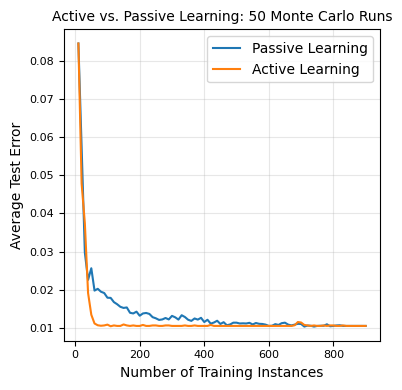

In [18]:
average_results = pd.DataFrame([training_sizes, passive_average_errors, active_average_errors],
            index=["Training Size","Passive Average Test Error","Active Average Test Error"])
display(average_results.style.format("{:.0f}", subset=pd.IndexSlice["Training Size", :]).format("{:.6f}",
        subset=pd.IndexSlice[["Passive Average Test Error", "Active Average Test Error"],:]))
plt.figure(figsize=(4, 4))
plt.plot(training_sizes, passive_average_errors, label="Passive Learning", linewidth=1.5)
plt.plot(training_sizes, active_average_errors, label="Active Learning", linewidth=1.5)
plt.xlabel("Number of Training Instances",  fontsize=10)
plt.ylabel("Average Test Error", fontsize=10)
plt.title("Active vs. Passive Learning: 50 Monte Carlo Runs", fontsize=10)
plt.legend(fontsize=10, loc='upper right')
plt.grid(alpha=0.3)
plt.tick_params(axis='both', labelsize=8)
plt.tight_layout()
plt.show()